# Power system load classification
**Assignment 2**

The task is to predict `Light_Load`, `Medium_Load`, or `Maximum_Load` for each 15-minute interval using its electrical readings and timestamp. Since the assignment asks for the last month as the test set, December is being reserved for testing.

The following steps cover the data issues, model comparisons, and final predictions. Run the cells in order, with `load_data.csv` beside the notebook.

In [12]:
import os
os.environ.setdefault('OMP_NUM_THREADS', '2')
os.environ.setdefault('MKL_NUM_THREADS', '2')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, ConfusionMatrixDisplay)
from threadpoolctl import threadpool_limits

SEED = 42
TARGET = 'Load_Type'
LABELS = ['Light_Load', 'Medium_Load', 'Maximum_Load']
SENSORS = ['Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh',
           'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)',
           'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor']
POWER_FACTORS = SENSORS[-2:]
NUMERIC = SENSORS + ['NSM']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
pd.set_option('display.max_columns', 20)

## 1. Start with the data
Before choosing a model, the analysis is starting with a check of the record structure and date coverage. Each row has six sensor readings, a timestamp, seconds from midnight (`NSM`), and the known `Load_Type`.

Since the dates follow day-month-year, that format is being specified during parsing. December is being set aside so model choices use earlier months.

In [13]:
DATA_PATH = Path('load_data.csv')
if not DATA_PATH.exists():
    raise FileNotFoundError('Open this notebook from Assignment_2, beside load_data.csv.')
raw = pd.read_csv(DATA_PATH)
assert set(raw.columns) == set(['Date_Time', TARGET] + NUMERIC), 'Unexpected schema'
raw['_source_row'] = np.arange(len(raw))
raw['timestamp'] = pd.to_datetime(raw['Date_Time'], format='%d-%m-%Y %H:%M', errors='raise')
assert raw['timestamp'].notna().all()
assert raw[TARGET].notna().all() and set(raw[TARGET]) == set(LABELS)
assert all(pd.api.types.is_numeric_dtype(raw[c]) for c in NUMERIC)
assert raw['timestamp'].dt.year.unique().tolist() == [2018]
test_start = raw['timestamp'].max().to_period('M').start_time
assert test_start == pd.Timestamp('2018-12-01')
development_raw = raw.loc[raw.timestamp < test_start].copy()
test_raw = raw.loc[raw.timestamp >= test_start].copy()
print(f'{len(raw):,} records, covering {raw.timestamp.min():%d %b %Y} '
      f'to {raw.timestamp.max():%d %b %Y}.')
print(f'January-November: {len(development_raw):,} records; '
      f'December: {len(test_raw):,} records before cleaning.')
display(raw[['Date_Time', 'Usage_kWh', 'NSM', TARGET]].head(3))

35,041 records, covering 01 Jan 2018 to 31 Dec 2018.
January-November: 32,064 records; December: 2,977 records before cleaning.


,Date_Time,Usage_kWh,NSM,Load_Type
0,01-01-2018 00:15,8.753692,900.000000,Light_Load
1,01-01-2018 00:30,4.000000,1800.000000,Light_Load
2,01-01-2018 00:45,3.240000,8070.880991,Light_Load


## 2. Fix the data issues
Since the checks are showing missing readings, power factors above 100%, and NSM values that disagree with the time, invalid readings are being marked as missing and NSM is being rebuilt from the timestamp. For example, 00:45 should give 2,700 seconds.

Incomplete rows are being kept to avoid losing useful examples. For repeated timestamps, the record with more usable readings is being retained. Large positive values are also staying in the data because they may be genuine high loads.

In [14]:
def clean_records(frame, deduplicate=True):
    out = frame.copy()
    out[SENSORS] = out[SENSORS].replace([np.inf, -np.inf], np.nan)
    out[SENSORS] = out[SENSORS].mask(out[SENSORS] < 0)
    out[POWER_FACTORS] = out[POWER_FACTORS].mask(out[POWER_FACTORS] > 100)
    out['NSM'] = out.timestamp.dt.hour * 3600 + out.timestamp.dt.minute * 60
    if TARGET in out:
        assert out.groupby('timestamp')[TARGET].nunique().max() == 1, 'Conflicting duplicate labels'
    out['_missing_sensors'] = out[SENSORS].isna().sum(axis=1)
    ordered = out.sort_values(['timestamp', '_missing_sensors', '_source_row'], kind='stable')
    discarded = ordered.loc[ordered.timestamp.duplicated(keep='first'),
                            ['timestamp', '_source_row', '_missing_sensors']].copy()
    # The optional all-row check retains duplicates without changing sensor cleaning.
    out = ordered.drop_duplicates('timestamp', keep='first') if deduplicate else ordered
    out = out.drop(columns='_missing_sensors')
    out = out.sort_values('timestamp').reset_index(drop=True)
    assert out.timestamp.is_monotonic_increasing
    if deduplicate:
        assert out.timestamp.is_unique
    return out, discarded

development, dropped_development = clean_records(development_raw)
expected_nsm = development_raw.timestamp.dt.hour * 3600 + development_raw.timestamp.dt.minute * 60
invalid_sensors = (~np.isfinite(development_raw[SENSORS]) & development_raw[SENSORS].notna())
invalid_sensors |= development_raw[SENSORS] < 0
invalid_sensors[POWER_FACTORS] |= development_raw[POWER_FACTORS] > 100
wrong_nsm = development_raw.NSM.notna() & ~np.isclose(development_raw.NSM, expected_nsm)
invalid_counts = invalid_sensors.sum().reindex(NUMERIC, fill_value=0)
invalid_counts['NSM'] = int(wrong_nsm.sum())
audit = pd.DataFrame({
    'Missing before': development_raw[NUMERIC].isna().sum(),
    'Invalid readings': invalid_counts,
    'Missing after': development[NUMERIC].isna().sum().values})
short_names = dict(zip(NUMERIC, ['Usage', 'Lagging reactive energy', 'Leading reactive energy',
    'CO2', 'Lagging power factor', 'Leading power factor', 'Seconds from midnight']))
display(audit.rename(index=short_names))
assert len(development) == 32064
assert development.timestamp.diff().dropna().eq(pd.Timedelta(minutes=15)).all()
assert development[POWER_FACTORS].stack().dropna().between(0, 100).all()
assert development.NSM.between(0, 85500).all()

,Missing before,Invalid readings,Missing after
Usage,1395,0,1395
Lagging reactive energy,795,0,795
Leading reactive energy,1057,0,1057
CO2,418,0,418
Lagging power factor,323,2922,3245
Leading power factor,1352,2459,3811
Seconds from midnight,404,3127,0


## 3. Look for patterns
With the main data issues addressed, the analysis is moving to class balance and label patterns by month, hour, and weekday. This helps in judging whether calendar features can add useful information.

The next step is comparing sensor readings across classes. Outlier dots are being hidden only for readability, while CO2 is being kept in its supplied units because the unit description is unclear.

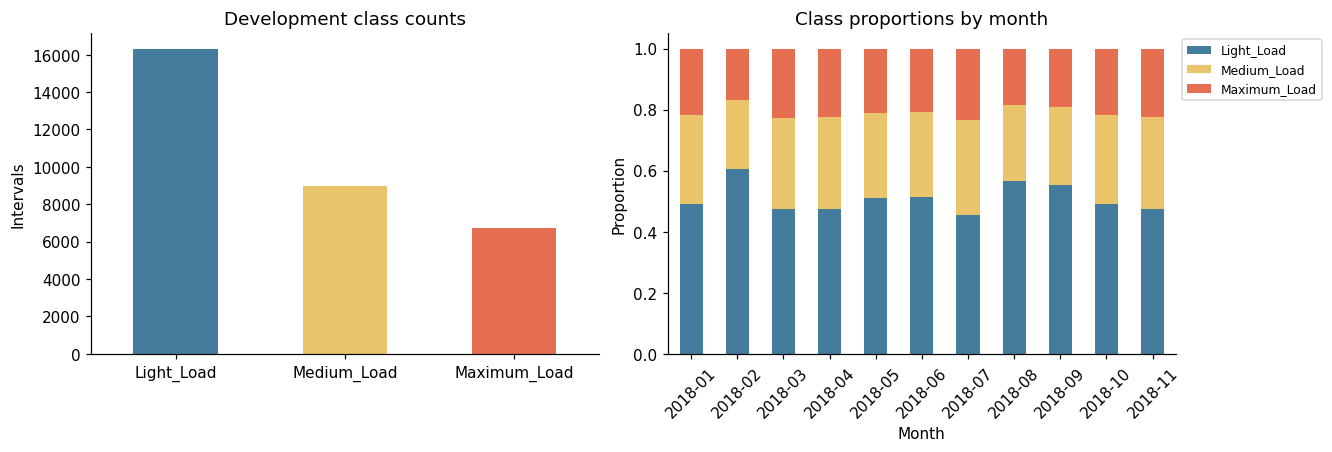

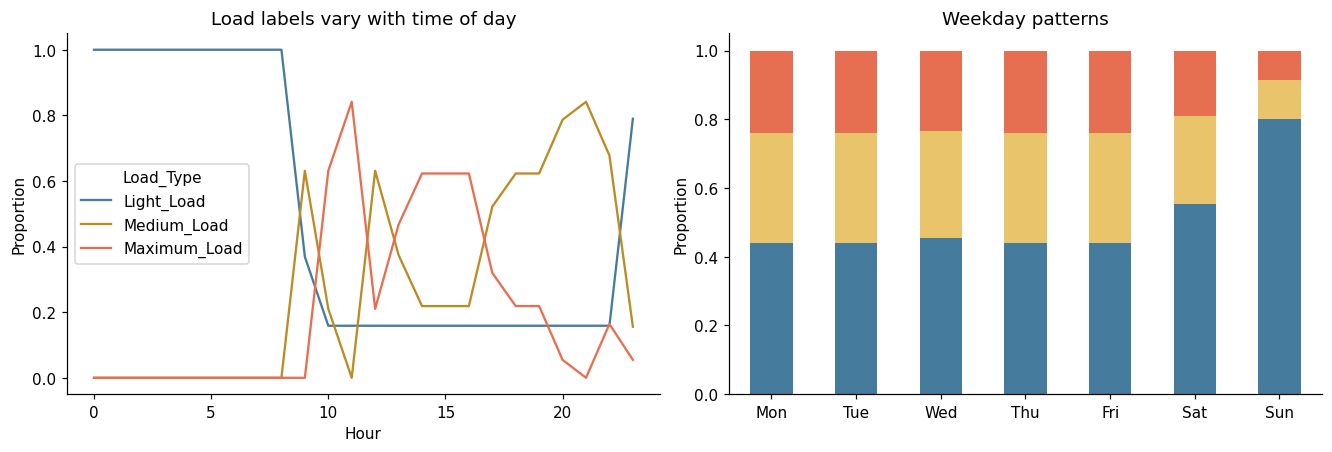

In [15]:
counts = development[TARGET].value_counts().reindex(LABELS)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
counts.plot.bar(ax=axes[0], color=['#457b9d', '#e9c46a', '#e76f51'], rot=0)
axes[0].set(title='Development class counts', ylabel='Intervals', xlabel='')
monthly = pd.crosstab(development.timestamp.dt.to_period('M'), development[TARGET], normalize='index')
monthly.reindex(columns=LABELS).plot.bar(stacked=True, ax=axes[1], rot=45,
                                        color=['#457b9d', '#e9c46a', '#e76f51'])
axes[1].set(title='Class proportions by month', ylabel='Proportion', xlabel='Month')
axes[1].legend(fontsize=8, loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
hourly = pd.crosstab(development.timestamp.dt.hour, development[TARGET], normalize='index')
hourly.reindex(columns=LABELS).plot(ax=axes[0], color=['#457b9d', '#bc8b23', '#e76f51'])
axes[0].set(title='Load labels vary with time of day', xlabel='Hour', ylabel='Proportion')
weekday = pd.crosstab(development.timestamp.dt.dayofweek, development[TARGET], normalize='index')
weekday.reindex(columns=LABELS).plot.bar(stacked=True, ax=axes[1], legend=False,
                                        color=['#457b9d', '#e9c46a', '#e76f51'])
axes[1].set_xticklabels(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'], rotation=0)
axes[1].set(title='Weekday patterns', xlabel='', ylabel='Proportion')
plt.show()

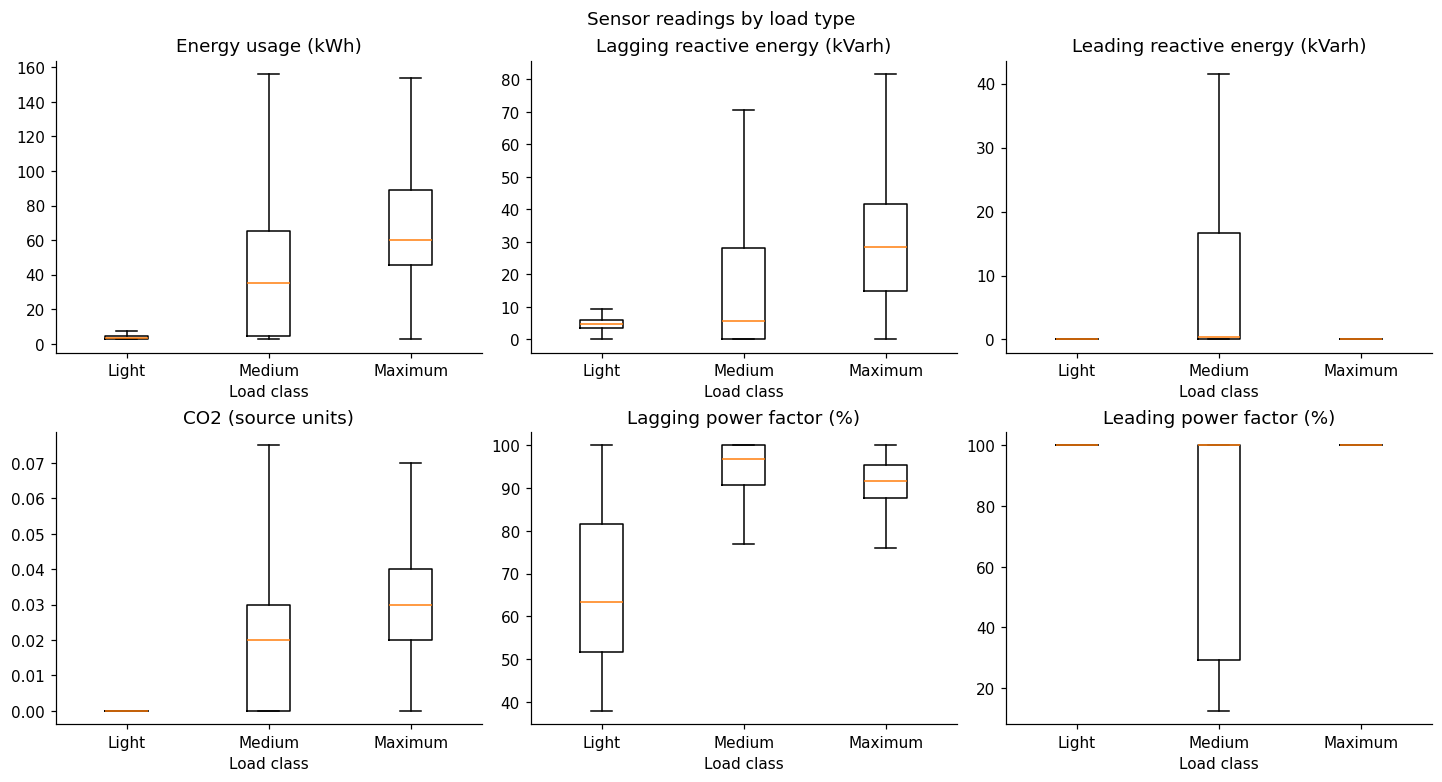

Light_Load accounts for about half the development records. Load labels vary with time and weekday, while sensor readings overlap between classes. This supports trying both sensor and calendar inputs.

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7), layout='constrained')
titles = ['Energy usage (kWh)', 'Lagging reactive energy (kVarh)',
          'Leading reactive energy (kVarh)', 'CO2 (source units)',
          'Lagging power factor (%)', 'Leading power factor (%)']
for ax, feature, title in zip(axes.flat, SENSORS, titles):
    values = [development.loc[development[TARGET] == label, feature].dropna() for label in LABELS]
    ax.boxplot(values, tick_labels=['Light', 'Medium', 'Maximum'], showfliers=False)
    ax.set(title=title, xlabel='Load class')
fig.suptitle('Sensor readings by load type', fontsize=12)
plt.show()


display(Markdown('Light_Load accounts for about half the development records. '
    'Load labels vary with time and weekday, while sensor readings overlap between classes. '
    'This supports trying both sensor and calendar inputs.'))

## 4. Turn the patterns into features
Since the plots are showing clear time and weekday patterns, time of day, weekday, weekend, and month are being added alongside the six sensors. Month is being encoded with sine/cosine to place December near January in the yearly cycle.

The inputs are going into `X` and the label into `y`, without scaling because tree models do not need it. Validation is using September, October, and November in turn, with training restricted to earlier records to check performance on later months.

In [17]:
CALENDAR = ['seconds_from_midnight', 'day_of_week', 'is_weekend', 'month_sin', 'month_cos']
FEATURE_SETS = {'combined': SENSORS + CALENDAR, 'calendar': CALENDAR, 'sensors': SENSORS}

def make_features(frame, feature_set='combined'):
    x = frame[SENSORS].copy()
    t = frame.timestamp
    x['seconds_from_midnight'] = frame['NSM']
    x['day_of_week'] = t.dt.dayofweek
    x['is_weekend'] = (t.dt.dayofweek >= 5).astype(int)
    angle = 2*np.pi*(t.dt.month-1)/12
    x['month_sin'], x['month_cos'] = np.sin(angle), np.cos(angle)
    return x[FEATURE_SETS[feature_set]].astype(float)

folds = []
fold_description = []
for month in [9, 10, 11]:
    start = pd.Timestamp(2018, month, 1)
    end = start + pd.offsets.MonthBegin(1)
    train_idx = np.flatnonzero(development.timestamp < start)
    valid_idx = np.flatnonzero((development.timestamp >= start) & (development.timestamp < end))
    assert development.iloc[train_idx].timestamp.max() < development.iloc[valid_idx].timestamp.min()
    assert set(development.iloc[train_idx][TARGET]) == set(LABELS)
    assert set(development.iloc[valid_idx][TARGET]) == set(LABELS)
    folds.append((start.strftime('%B'), train_idx, valid_idx))
    fold_description.append({'Training months': f'January-{(start - pd.Timedelta(days=1)):%B}',
                             'Validation month': start.strftime('%B')})
display(pd.DataFrame(fold_description))
assert TARGET not in make_features(development).columns
assert '_source_row' not in make_features(development).columns
# Deterministic transformations cannot depend on the target.
pd.testing.assert_frame_equal(make_features(development), make_features(development.drop(columns=TARGET)))

,Training months,Validation month
0,January-August,September
1,January-September,October
2,January-October,November


## 5. Find a suitable model
Model comparison is starting with a majority-class baseline and a decision tree, followed by Random Forest and boosting to check whether more flexible models help. Tree size is being limited to reduce overfitting, and missing-value replacements are being learned within each training fold.

Since Light_Load is more common, selection is using average macro F1 to give all three classes equal weight. Boosting handles missing values directly; its automatic early stopping is being disabled to avoid an internal random split.

In [18]:
def imputed(estimator):
    return Pipeline([('imputer', SimpleImputer(strategy='median', add_indicator=True)),
                     ('model', estimator)])


def hgb(leaves=15, iterations=150, minimum=30):
    return HistGradientBoostingClassifier(
        max_leaf_nodes=leaves, max_iter=iterations, min_samples_leaf=minimum,
        learning_rate=0.1, l2_regularization=1.0,
        early_stopping=False, random_state=SEED)


# Each candidate contains its input group and an unfitted model.
candidates = {
    'Dummy': ('combined', DummyClassifier(strategy='most_frequent')),
    'Tree_depth6': ('combined', imputed(DecisionTreeClassifier(
        max_depth=6, min_samples_leaf=30, random_state=SEED))),
    'Tree_depth10': ('combined', imputed(DecisionTreeClassifier(
        max_depth=10, min_samples_leaf=30, random_state=SEED))),
    'RandomForest': ('combined', imputed(RandomForestClassifier(
        n_estimators=120, max_depth=12, min_samples_leaf=10,
        max_features=0.8, n_jobs=2, random_state=SEED))),
    'HGB_small': ('combined', hgb(7, 100, 50)),
    'HGB_main': ('combined', hgb()),
    'HGB_200': ('combined', hgb(15, 200, 30)),
    'HGB_calendar': ('calendar', hgb()),
    'HGB_sensors': ('sensors', hgb()),
}
X_sets = {name: make_features(development, name) for name in FEATURE_SETS}
y_dev = development[TARGET]
results = []

for name, (feature_set, estimator) in candidates.items():
    x = X_sets[feature_set]
    for month, train_idx, valid_idx in folds:
        fitted = clone(estimator)  # Start fresh for each training period.
        with threadpool_limits(limits=2):
            fitted.fit(x.iloc[train_idx], y_dev.iloc[train_idx])
            pred = fitted.predict(x.iloc[valid_idx])
        results.append({'candidate': name, 'month': month,
            'macro_f1': f1_score(y_dev.iloc[valid_idx], pred,
                                 labels=LABELS, average='macro')})

validation_results = pd.DataFrame(results)
monthly_scores = validation_results.pivot(
    index='candidate', columns='month', values='macro_f1')
summary = monthly_scores.reindex(columns=['September', 'October', 'November']).copy()
summary.insert(0, 'mean_macro_f1', summary.mean(axis=1))
summary = summary.sort_values('mean_macro_f1', ascending=False)
summary.columns.name = None
display(summary.round(4).rename(columns={'mean_macro_f1': 'Mean macro F1'}))

selected_name = summary.drop(index='Dummy')['mean_macro_f1'].idxmax()
selected_features, selected_template = candidates[selected_name]
display(Markdown(f'**Selected: {selected_name}**, with {selected_features} inputs. '
    f'Mean validation macro F1: **{summary.loc[selected_name, "mean_macro_f1"]:.4f}**.'))

,Mean macro F1,September,October,November
candidate,,,,
HGB_small,0.8414,0.9388,0.9895,0.5957
HGB_200,0.8384,0.9335,0.9852,0.5964
HGB_main,0.8374,0.9324,0.9841,0.5959
RandomForest,0.8361,0.9306,0.9851,0.5925
Tree_depth6,0.8293,0.9212,0.9793,0.5874
Tree_depth10,0.8292,0.9152,0.9795,0.5929
HGB_calendar,0.8043,0.8375,1.0000,0.5753
HGB_sensors,0.6662,0.6759,0.7139,0.6087
Dummy,0.2239,0.2373,0.2198,0.2147


**Selected: HGB_small**, with combined inputs. Mean validation macro F1: **0.8414**.

The small boosting model is giving the best average score, so it is being selected over the larger settings. Since November's score is dropping sharply, the next step is checking changes in time patterns before drawing conclusions from the average.

## 6. Understand the November drop
To see what is helping the predictions, this comparison is using sensors alone, calendar features alone, and both together with the same boosting settings.

Since November is performing worse, the usual label at each time of day is also being compared between October and November. Changes here may help explain why training on earlier months is not enough.

In [19]:
group_scores = summary.loc[['HGB_sensors', 'HGB_calendar', 'HGB_main'],
                           ['mean_macro_f1', 'November']].copy()
group_scores.index = ['Sensors only', 'Calendar only', 'Combined']
display(group_scores.round(4).rename(columns={'mean_macro_f1': 'Mean macro F1'}))

# Compare label patterns using development data only.
time_slot = development['NSM'] // 900
slot_modes = {}
for month in [10, 11]:
    rows = development.timestamp.dt.month.eq(month)
    slot_modes[month] = pd.crosstab(
        time_slot[rows], development.loc[rows, TARGET]).idxmax(axis=1)
changed_slots = int((slot_modes[10] != slot_modes[11]).sum())
print(f'Most common class changed in {changed_slots} of 96 daily time slots.')

,Mean macro F1,November
Sensors only,0.6662,0.6087
Calendar only,0.8043,0.5753
Combined,0.8374,0.5959


Most common class changed in 32 of 96 daily time slots.


The comparison is showing stronger results from calendar features than sensors alone, with combined inputs improving the average. Since the usual label is changing in 32 of 96 daily time slots between October and November, a schedule change is being considered as a possible explanation, rather than a confirmed cause.

## 7. Test the selected model on December
With the model selected, it is being fitted on January-November and evaluated on December using the same cleaning rules. Its settings are staying fixed; December was already scored in the earlier version.

The evaluation is using accuracy for overall correctness and precision, recall, and F1 for each class. A confusion matrix is being plotted to show which labels are being mixed up.

,Accuracy,Macro F1
model,,
Majority baseline,0.5860,0.2463
HGB_small,0.9519,0.9474


,precision,recall,f1-score,Intervals
Light_Load,0.9425,0.9776,0.9598,1744
Medium_Load,0.9738,0.8977,0.9342,704
Maximum_Load,0.9575,0.9394,0.9484,528


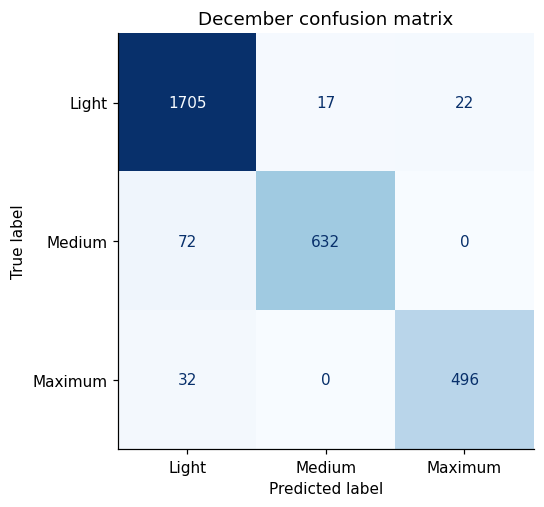

In [20]:
test, dropped_test = clean_records(test_raw)
assert len(test) == 2976
assert development.timestamp.max() < test.timestamp.min()
assert test.timestamp.diff().dropna().eq(pd.Timedelta(minutes=15)).all()

final_model = clone(selected_template)
X_train_final = X_sets[selected_features]
X_test = make_features(test, selected_features)
y_test = test[TARGET]
with threadpool_limits(limits=2):
    final_model.fit(X_train_final, y_dev)
    test_pred = final_model.predict(X_test)

dummy = DummyClassifier(strategy='most_frequent').fit(
    np.zeros((len(y_dev), 1)), y_dev)
dummy_pred = dummy.predict(np.zeros((len(y_test), 1)))
test_metrics = pd.DataFrame([
    {'model': name, 'accuracy': accuracy_score(y_test, pred),
     'macro_precision': precision_score(y_test, pred, labels=LABELS,
                                         average='macro', zero_division=0),
     'macro_recall': recall_score(y_test, pred, labels=LABELS,
                                   average='macro', zero_division=0),
     'macro_f1': f1_score(y_test, pred, labels=LABELS, average='macro')}
    for name, pred in [('Majority baseline', dummy_pred), (selected_name, test_pred)]
]).set_index('model')
display(test_metrics[['accuracy', 'macro_f1']].round(4).rename(
    columns={'accuracy': 'Accuracy', 'macro_f1': 'Macro F1'}))
report = pd.DataFrame(classification_report(
    y_test, test_pred, labels=LABELS, output_dict=True, zero_division=0)).T
# Class rows give precision, recall, F1, and the number of intervals (support).
class_report = report.loc[LABELS].round(4).copy()
class_report['support'] = class_report['support'].astype(int)
display(class_report.rename(columns={'support': 'Intervals'}))
fig, ax = plt.subplots(figsize=(6, 4.5), layout='constrained')
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, labels=LABELS, display_labels=['Light', 'Medium', 'Maximum'],
    values_format='d', cmap='Blues', ax=ax, colorbar=False)
ax.set_title('December confusion matrix')
plt.show()

# Check the duplicate's effect using the same fitted model.
test_all_rows, _ = clean_records(test_raw, deduplicate=False)
with threadpool_limits(limits=2):
    all_pred = final_model.predict(make_features(test_all_rows, selected_features))
all_row_accuracy = accuracy_score(test_all_rows[TARGET], all_pred)
# The duplicate check is summarized below rather than displayed as another table.
duplicate_accuracy_change = all_row_accuracy - test_metrics.loc[selected_name, 'accuracy']

## 8. Check the main mistakes
Since a strong overall score can hide a weaker class, error analysis is focusing on which labels are being confused most often. A few misclassified records are also being inspected to make that weakness easier to understand.

In [21]:
errors = test[['timestamp', TARGET]].copy()
errors['prediction'] = test_pred
mistakes = errors.loc[errors[TARGET] != errors.prediction]
medium_as_light = int(((mistakes[TARGET] == 'Medium_Load') &
                       (mistakes.prediction == 'Light_Load')).sum())
display(mistakes.head(3).rename(columns={
    'timestamp': 'Time', TARGET: 'Actual', 'prediction': 'Predicted'}))
display(Markdown(f'There are **{len(mistakes)} errors out of {len(test):,} intervals**. '
    f'The largest group is {medium_as_light} Medium_Load intervals predicted as Light_Load.'))

,Time,Actual,Predicted
48,2018-12-01 12:00:00,Maximum_Load,Light_Load
49,2018-12-01 12:15:00,Medium_Load,Light_Load
50,2018-12-01 12:30:00,Medium_Load,Light_Load


There are **143 errors out of 2,976 intervals**. The largest group is 72 Medium_Load intervals predicted as Light_Load.

Since Medium_Load is showing the lowest recall, it is being identified as the main December weakness. The duplicate check is showing almost no change in accuracy, so its effect is being treated as negligible.

## 9. What the results tell us
The small boosting model is achieving **95.19% December accuracy** and **0.9474 macro F1**, well above the majority baseline. Combining sensor and calendar inputs is helping, but November's drop is highlighting a weakness when time patterns change.

Since the data covers one year from one apparent industrial source, the conclusions are being limited to this dataset. Large positive sensor errors may remain because reliable upper bounds are unavailable. The model is classifying intervals whose readings are already available; future forecasting would need a different setup.

## Model used

- [scikit-learn Histogram Gradient Boosting](https://scikit-learn.org/1.7/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html)